# Стратегии чанкинга: эксперименты и сравнение поиска по разным БД

Стенд сравнивает контролируемые LangChain-стратегии на одном корпусе Markdown-инструкций и одном golden dataset.

| Стратегия | Проверяемая гипотеза | Реализация |
|---|---|---|
| `baseline-1200-120` | production-контроль | проектный `split_text`; известный недостаток: overlap может начинаться внутри слова |
| `markdown-recursive-800-80` | меньшие структурные чанки | LangChain `RecursiveCharacterTextSplitter.from_language(MARKDOWN)` |
| `markdown-recursive-1200-120` | текущий размер без production-overlap | тот же LangChain splitter |
| `markdown-recursive-1600-160` | больше контекста | тот же LangChain splitter |
| `markdown-headers-contextual-1200` | контекст заголовков помогает retrieval | `MarkdownHeaderTextSplitter` + breadcrumbs внутри общего лимита 1200 |
| `markdown-blocks` | упаковка по пустым строкам полезнее обычного recursive | Markdown-блоки; слишком большие блоки режутся recursive fallback |
| `semantic-ollama-p90-capped-1200` | больше семантических границ | LangChain `SemanticChunker`, percentile 90, затем capped recursive fallback |
| `semantic-ollama-p95-capped-1200` | более редкие семантические границы | LangChain `SemanticChunker`, percentile 95, затем capped recursive fallback |

`fixed-512-64` и `sentence-window` исключены из default-набора: первый удваивал индекс без прироста hit@3, второй создавал много коротких и дублирующих хвостовых окон. Их старые артефакты не удаляются.

Не включены parent-child и agentic chunking: первая требует отдельного retrieval-контракта, вторая недетерминированна и дорога.

**Границы записи:** production-дамп и production-БД только читаются. Все экспериментальные дампы, `.lbdb`, `run.json` и `results.json` пишутся в `runtime/debug/chunking-experiments/`.

Порядок: Run All сверху вниз. Настройки — только в ячейке CONFIG.


## 1. Корень проекта и ядро

Ноутбук должен работать на ядре основного окружения проекта `mvp_v2/.venv`
(python из `mvp_v2/.venv`).

In [1]:
from __future__ import annotations

import importlib
import json
import os
import sys
import time
from datetime import UTC, datetime
from pathlib import Path
from typing import Any

import pandas as pd
from dotenv import load_dotenv


def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src").is_dir():
            return candidate
        nested = candidate / "mvp_v2"
        if (nested / "pyproject.toml").is_file() and (nested / "src").is_dir():
            return nested
    raise RuntimeError("Run this notebook from the repository or mvp_v2 directory")


PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))


load_dotenv(PROJECT_ROOT / ".env", override=True)
print("Project:", PROJECT_ROOT)
print("Kernel:", sys.executable)

Project: /Users/zero/GITHUB/vue-graph-rag/mvp_v2
Kernel: /Users/zero/GITHUB/vue-graph-rag/mvp_v2/.venv/bin/python


## 2. CONFIG - единственная ячейка настроек

Меняйте только эту ячейку. По умолчанию собираются все 7 стратегий по всем
текущим `.md`-документам; для быстрого прогона уберите стратегии из `STRATEGIES`,
поставьте `MAX_DOCUMENTS = 5` или выключите `BUILD_DATABASES` (только статистика чанков).

In [4]:

# ===================== CONFIG: меняйте только здесь =====================

# Исходная база: None = самая свежая проверенная .lbdb из runtime/databases,
# иначе имя базы без суффикса, например "rag-db".
SOURCE_DATABASE_NAME: str | None = None

# Стратегии чанкинга: одна экспериментальная БД на стратегию.
# "baseline-1200-120" - контроль: та же нарезка, что в продакшен-инжесте.
STRATEGIES: tuple[str, ...] = (
    "baseline-1200-120",
    "markdown-recursive-800-80",
    "markdown-recursive-1200-120",
    "markdown-recursive-1600-160",
    "markdown-headers-contextual-1200",
    "markdown-blocks",
    "semantic-ollama-p90-capped-1200",
    "semantic-ollama-p95-capped-1200",
)

# Параметры стратегий (размеры в символах).
STRATEGY_PARAMS: dict[str, dict[str, Any]] = {
    "baseline-1200-120": {"max_characters": 1_200, "overlap_characters": 120},
    "markdown-recursive-800-80": {"chunk_size": 800, "chunk_overlap": 80},
    "markdown-recursive-1200-120": {"chunk_size": 1_200, "chunk_overlap": 120},
    "markdown-recursive-1600-160": {"chunk_size": 1_600, "chunk_overlap": 160},
    "markdown-headers-contextual-1200": {"chunk_size": 1_200, "chunk_overlap": 120},
    "markdown-blocks": {"max_characters": 1_200},
    "semantic-ollama-p90-capped-1200": {
        "breakpoint_threshold_amount": 90.0,
        "chunk_size": 1_200,
        "chunk_overlap": 120,
    },
    "semantic-ollama-p95-capped-1200": {
        "breakpoint_threshold_amount": 95.0,
        "chunk_size": 1_200,
        "chunk_overlap": 120,
    },
}

# Документы: None = все текущие .md-версии; число = первые N (быстрый прогон).
MAX_DOCUMENTS: int | None = None

# Голден-кейсы для сравнения поиска (одни и те же кейсы -> все стратегии).
# Набор задан в ячейке golden-cases ниже; здесь только ограничение выборки:
# None = все кейсы; число = первые N по порядку (быстрый прогон).
CASE_LIMIT: int | None = None

EVIDENCE_LIMIT = 3               # топ-N доказательств (1..100)
MINIMUM_SIMILARITY_SCORE = 0.55  # порог косинус-близости (-1..1)

# Этапы прогона: False = только превью статистики чанков (быстро, без Ollama).
BUILD_DATABASES = True           # собрать вариантные дампы и .lbdb (зовёт Ollama-эмбеддинги)
RUN_SEARCH = True                # прогнать голден-кейсы по собранным БД

PREVIEW_CHARACTERS = 200         # сколько символов чанка показывать в превью
GENERATION_TEMPERATURE = 0.0
OLLAMA_TIMEOUT_SECONDS = 120.0

# Опциональный LLM-as-judge поверх уже найденного retrieval-контекста.
# Детерминированные метрики выше остаются основными.
RUN_DEEPEVAL_JUDGE = False
DEEPEVAL_CASE_LIMIT = 10
DEEPEVAL_STRATEGIES: tuple[str, ...] = (
    "baseline-1200-120",
    "markdown-recursive-800-80",
    "markdown-recursive-1200-120"
)
DEEPEVAL_THRESHOLD = 0.6
DEEPEVAL_JUDGE_MODEL = (
    os.environ.get("MVP_V2_DEEPEVAL_JUDGE_MODEL", "").strip()
    or "gpt-oss:20b"
)

# Куда писать: runtime/debug/chunking-experiments/<дата>/<run_id>/{dumps,db,...}.
RUNS_ROOT = PROJECT_ROOT / "runtime/debug/chunking-experiments"

# Реюз БД: None = собирать все стратегии заново; иначе каталог прошлого прогона
# (абсолютный путь или относительно RUNS_ROOT, например
# "2026-10-22/20261022T142111.787317Z") - стратегии с готовой БД в <прогон>/db
# пропускают сборку и берутся оттуда.
REUSE_FROM_RUN: str | None = None

# --- проверки значений ---
unknown = [name for name in STRATEGIES if name not in STRATEGY_PARAMS]
if unknown:
    raise ValueError(f"Неизвестные стратегии в STRATEGIES: {unknown}")
if not STRATEGIES:
    raise ValueError("STRATEGIES пуст: выберите хотя бы одну стратегию")
if MAX_DOCUMENTS is not None and MAX_DOCUMENTS < 1:
    raise ValueError("MAX_DOCUMENTS: None или >= 1")
if CASE_LIMIT is not None and CASE_LIMIT < 1:
    raise ValueError("CASE_LIMIT: None или >= 1")
if not 1 <= DEEPEVAL_CASE_LIMIT <= 10:
    raise ValueError("DEEPEVAL_CASE_LIMIT должен быть от 1 до 10")
if len(DEEPEVAL_STRATEGIES) != 3 or len(set(DEEPEVAL_STRATEGIES)) != 3:
    raise ValueError("DEEPEVAL_STRATEGIES должен содержать 3 разные стратегии")
unknown_judge_strategies = [
    name for name in DEEPEVAL_STRATEGIES if name not in STRATEGIES
]
if unknown_judge_strategies:
    raise ValueError(
        f"DEEPEVAL_STRATEGIES отсутствуют в STRATEGIES: {unknown_judge_strategies}"
    )
if not 0.0 <= DEEPEVAL_THRESHOLD <= 1.0:
    raise ValueError("DEEPEVAL_THRESHOLD должен быть в диапазоне [0, 1]")
if not DEEPEVAL_JUDGE_MODEL:
    raise ValueError("DEEPEVAL_JUDGE_MODEL не задан")
if REUSE_FROM_RUN is not None:
    reuse_candidate = Path(REUSE_FROM_RUN)
    if not reuse_candidate.is_absolute():
        reuse_candidate = RUNS_ROOT / reuse_candidate
    if not reuse_candidate.is_dir():
        raise ValueError(f"REUSE_FROM_RUN не найден: {reuse_candidate}")
if not 1 <= EVIDENCE_LIMIT <= 100:
    raise ValueError("EVIDENCE_LIMIT должен быть от 1 до 100")
if not -1.0 <= MINIMUM_SIMILARITY_SCORE <= 1.0:
    raise ValueError("MINIMUM_SIMILARITY_SCORE должен быть в диапазоне [-1, 1]")
print(
    "CONFIG ok:",
    len(STRATEGIES), "стратегий;",
    "документов", "все" if MAX_DOCUMENTS is None else MAX_DOCUMENTS,
    "; сборка БД", "вкл" if BUILD_DATABASES else "выкл",
    "; поиск", "вкл" if RUN_SEARCH else "выкл",
)

CONFIG ok: 8 стратегий; документов все ; сборка БД вкл ; поиск вкл


In [5]:
# ===== GOLDEN CASES: единый источник — notebooks/golden_dataset.json =====
from dataclasses import asdict, dataclass
from typing import Literal


@dataclass(frozen=True, slots=True)
class GoldenCase:
    case_id: str
    question: str
    ground_truth: str
    kind: Literal["answer", "refusal"] = "answer"
    status: Literal["candidate", "needs_review"] = "candidate"
    alternatives: tuple[str, ...] = ()
    expected_documents: tuple[str, ...] = ()


golden_path = PROJECT_ROOT / "notebooks" / "golden_dataset.json"
golden_payload = json.loads(golden_path.read_text(encoding="utf-8"))
GOLDEN_CASES = tuple(
    GoldenCase(
        case_id=item["case_id"],
        question=item["question"],
        ground_truth=item.get("rationale", ""),
        kind="refusal" if item["kind"] == "refusal" else "answer",
        status=(
            "needs_review"
            if item.get("confidence") in {"low", "medium"}
            else "candidate"
        ),
        expected_documents=tuple(item.get("expected_documents") or ()),
    )
    for item in golden_payload["cases"]
)
assert len(GOLDEN_CASES) == len({case.case_id for case in GOLDEN_CASES})
refusal_count = sum(case.kind == "refusal" for case in GOLDEN_CASES)
unlabeled_count = sum(
    case.kind == "answer" and not case.expected_documents
    for case in GOLDEN_CASES
)
print(
    "Кейсы:", len(GOLDEN_CASES),
    "answer:", len(GOLDEN_CASES) - refusal_count,
    "refusal:", refusal_count,
    "без разметки:", unlabeled_count,
)

SELECTED_CASES: tuple[GoldenCase, ...] = (
    GOLDEN_CASES if CASE_LIMIT is None else GOLDEN_CASES[:CASE_LIMIT]
)
print(
    "Выбрано кейсов:", len(SELECTED_CASES), "из", len(GOLDEN_CASES),
    "(CASE_LIMIT =", CASE_LIMIT, ")",
)


Кейсы: 70 answer: 65 refusal: 5 без разметки: 1
Выбрано кейсов: 70 из 70 (CASE_LIMIT = None )


## 3. Импорты: полный сброс и повторный импорт с диска

Перед импортом все модули проекта удаляются из `sys.modules`: каждый класс
`vue_rag` существует в ядре ровно в одном экземпляре (частичный reload по
списку оставлял в обойдённых модулях старые классы и ломал Pydantic-валидацию).
После правок кода проекта просто снова Run All.
LangChain-сплиттеры - из зависимостей проекта (`langchain-text-splitters`,
`langchain-experimental`).

In [6]:
# Защита от протухшего ядра: старый пакет mvp_v2 убирается только перезапуском.
_STALE_MODULES = [name for name in sys.modules if name == "mvp_v2" or name.startswith("mvp_v2.")]
if _STALE_MODULES:
    raise RuntimeError(
        "В ядре загружены модули старого пакета mvp_v2. "
        "Перезапустите ядро (Kernel → Restart Kernel) и выполните Run All."
    )

# Полный сброс модулей проекта: удаляем из sys.modules, и импорты ниже заново
# читают код с диска. Так каждый класс vue_rag существует в ядре ровно в одном
# экземпляре. Частичный reload по ручному списку оставлял в модулях вне списка
# старые классы: adapters/csv/snapshot.py создавал DumpFileEntry старой версии,
# а adapters/filesystem/dumps.py ждал новую -> ValidationError у DumpManifest.
for _module_name in [
    name
    for name in sys.modules
    if name == "vue_rag"
    or name.startswith("vue_rag.")
    or name == "src.vue_rag"
    or name.startswith("src.vue_rag.")
]:
    del sys.modules[_module_name]

import vue_rag.application.ingestion_contracts as ingestion_contracts_module
import vue_rag.application.dto.retrieval as retrieval_dto_module
import vue_rag.application.dump_lifecycle.manifests as manifests_module
import vue_rag.domain.graph as graph_module
import vue_rag.domain.snapshot as snapshot_module
import vue_rag.application.rag.preparation.chunking as chunking_module
import vue_rag.application.rag.preparation.chunk_backfill as chunk_backfill_module
import vue_rag.adapters.filesystem.media as media_module
import vue_rag.adapters.filesystem.dumps as dumps_module
import vue_rag.adapters.ladybug as ladybug_adapter_module
import vue_rag.adapters.ollama as ollama_module
import vue_rag.application.rag.preparation.model_operations as model_operations_module
import vue_rag.application.dump_lifecycle.publication as publication_module
import vue_rag.application.dump_lifecycle.validation as validation_module
import vue_rag.application.rag.retrieval.retrieval as retrieval_module
import vue_rag.bootstrap.ui as bootstrap_ui_module
import vue_rag.streamlit_ui.controller as controller_module
import vue_rag.backend.runtime as backend_runtime_module

# Свежие имена из заново импортированных модулей.
ModelAuthorization = ingestion_contracts_module.ModelAuthorization
ModelIdentity = ingestion_contracts_module.ModelIdentity
EmbeddingRequest = ingestion_contracts_module.EmbeddingRequest
SearchRequest = retrieval_dto_module.SearchRequest
EmbeddingPurpose = retrieval_dto_module.EmbeddingPurpose
graph = graph_module
GraphSnapshot = snapshot_module.GraphSnapshot
ChunkPolicy = chunking_module.ChunkPolicy
split_text = chunking_module.split_text
make_chunks = chunking_module.make_chunks
sanitize_source_text = chunk_backfill_module._sanitize_source_text
FilesystemMediaResolver = media_module.FilesystemMediaResolver
FilesystemDumpRepository = dumps_module.FilesystemDumpRepository
load_verified_dump = ladybug_adapter_module.load_verified_dump
build_database = ladybug_adapter_module.build_database
load_database_manifest = backend_runtime_module.load_database_manifest
LadybugAnn = ladybug_adapter_module.LadybugAnn
LocalHttpTransport = ollama_module.LocalHttpTransport
OllamaAdapter = ollama_module.OllamaAdapter
build_embeddings = model_operations_module.build_embeddings
SnapshotPublicationService = publication_module.SnapshotPublicationService
validate_snapshot = validation_module.validate_snapshot
SearchService = retrieval_module.SearchService
default_runtime_config = bootstrap_ui_module.default_runtime_config
configure_ladybug_home = controller_module.configure_ladybug_home
scan_database_manifests = controller_module.scan_database_manifests
database_is_stale = controller_module.database_is_stale

# LangChain-сплиттеры (зависимости проекта: langchain-text-splitters,
# langchain-experimental). SemanticChunker тянет langchain_core.
try:
    from langchain_text_splitters import (
        CharacterTextSplitter,
        Language,
        MarkdownHeaderTextSplitter,
        RecursiveCharacterTextSplitter,
    )
    from langchain_core.embeddings import Embeddings
    from langchain_experimental.text_splitter import SemanticChunker
except ImportError as error:
    raise RuntimeError(
        "Нужны langchain-text-splitters и langchain-experimental: "
        "выполните uv sync для mvp_v2"
    ) from error

# Защита от устаревших типов в живом ядре.
if "minimum_score" not in SearchRequest.model_fields:
    raise RuntimeError("SearchRequest устарел: перезапустите ядро и Run All")
if "generation_token" not in EmbeddingRequest.model_fields:
    raise RuntimeError("EmbeddingRequest устарел: перезапустите ядро и Run All")
print("Модули проекта заново импортированы с диска")

Модули проекта заново импортированы с диска


/var/folders/67/2wtrv_c91pbdshyhpbkydl680000gn/T/ipykernel_8569/3592857477.py:82: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.text_splitter import SemanticChunker


## 4. Исходная БД, дамп и документы (read-only)

Берём проверенную БД и её исходный дамп, читаем тексты текущих `.md`-версий
и готовим Ollama-адаптер (он нужен и для семантической нарезки, и для
эмбеддингов новых чанков). Продакшен-данные не меняются.

In [7]:
config = default_runtime_config()
verified_databases = scan_database_manifests(config.databases_root)
if not verified_databases:
    raise RuntimeError(
        "Проверенные БД не найдены в "
        + str(config.databases_root)
        + "; постройте базу через Streamlit или Telegram"
    )

if SOURCE_DATABASE_NAME is None:
    database_path, database_manifest = max(
        verified_databases, key=lambda item: item[1].built_at
    )
    print("SOURCE_DATABASE_NAME = None -> выбрана новейшая БД по built_at")
else:
    wanted = (
        SOURCE_DATABASE_NAME
        if SOURCE_DATABASE_NAME.endswith(".lbdb")
        else SOURCE_DATABASE_NAME + ".lbdb"
    )
    selected = [item for item in verified_databases if item[0].name == wanted]
    if len(selected) != 1:
        raise RuntimeError(
            f"Проверенная БД {wanted!r} не найдена однозначно в {config.databases_root}"
        )
    database_path, database_manifest = selected[0]

source_dump_path = (
    config.dumps_root / f"dump-{database_manifest.source_dump_number:06d}"
)
dump_manifest, snapshot = load_verified_dump(source_dump_path)
if database_is_stale(database_manifest, dump_manifest):
    raise RuntimeError("Манифест БД не совпадает с исходным дампом")

print("Database   :", database_path.name)
print("Source dump:", source_dump_path.name, "run", dump_manifest.run_id)
print("Space      :", database_manifest.embedding_space.model_dump(mode="json"))
print(
    "Snapshot   : документов", len(snapshot.documents),
    "| версий", len(snapshot.document_versions),
    "| чанков", len(snapshot.chunks),
    "| эмбеддингов", len(snapshot.embeddings),
)

# --- текущие .md-версии и их тексты ---
resolver = FilesystemMediaResolver(config.working_root)
current_md_versions = sorted(
    (
        version
        for version in snapshot.document_versions
        if version.is_current
        and version.local_path
        and version.local_path.endswith(".md")
    ),
    key=lambda version: version.local_path or "",
)
if not current_md_versions:
    raise RuntimeError("В дампе нет текущих .md-версий документов")
if MAX_DOCUMENTS is not None:
    current_md_versions = current_md_versions[:MAX_DOCUMENTS]
SELECTED_VERSIONS = tuple(current_md_versions)

document_titles = {document.id: document.title for document in snapshot.documents}
version_title = {
    edge.target_id: document_titles.get(edge.source_id, edge.source_id)
    for edge in snapshot.has_versions
}
SOURCES: dict[str, str] = {}
for version in SELECTED_VERSIONS:
    raw_text = resolver.read_verified(version.local_path, version.sha256).decode("utf-8")
    # Контракт Chunk разрешает только LF/TAB: санитизируем, как chunk_backfill в проде.
    SOURCES[version.id] = sanitize_source_text(raw_text)
    if SOURCES[version.id] != raw_text:
        print(f"санитизирован (control-символы): {version.local_path}")
print("Документов выбрано:", len(SOURCES))
for version in SELECTED_VERSIONS[:10]:
    print(f"  {version_title.get(version.id, '?')!r} <- {version.local_path}")
if len(SELECTED_VERSIONS) > 10:
    print(f"  ... и ещё {len(SELECTED_VERSIONS) - 10}")

# --- пре-чек публикации: файлы всех версий снимка должны существовать ---
# Гейт публикации проверяет sha256 КАЖДОЙ версии, включая старые (is_current=False).
# Удалённые с диска файлы исключаем каскадом: версия + её чанки/эмбеддинги + все связи.
unverifiable: list[tuple[str, str]] = []
for version in snapshot.document_versions:
    if not version.local_path:
        continue
    try:
        status = resolver.verify(version.local_path, version.sha256).status
    except Exception:
        status = "missing"
    if status != "verified":
        unverifiable.append((version.id, version.local_path))
if unverifiable:
    print("Исключаю версии без проверяемых файлов (удалённые источники):")
    for _version_id, local_path in unverifiable:
        print(f"  {local_path}")

removed_version_ids = {version_id for version_id, _ in unverifiable}
removed_chunk_ids = {
    edge.target_id
    for edge in snapshot.has_chunks
    if edge.source_id in removed_version_ids
}
removed_embedding_ids = {
    edge.target_id
    for edge in snapshot.has_embedding_chunks
    if edge.source_id in removed_chunk_ids
}
still_used = (
    {
        edge.target_id
        for edge in snapshot.has_embedding_chunks
        if edge.source_id not in removed_chunk_ids
    }
    | {edge.target_id for edge in snapshot.has_embedding_assets}
    | {edge.target_id for edge in snapshot.has_summary_embeddings}
)
removed_embedding_ids -= still_used
removed_node_ids = removed_version_ids | removed_chunk_ids | removed_embedding_ids
update: dict[str, Any] = {
    "document_versions": tuple(
        v for v in snapshot.document_versions if v.id not in removed_version_ids
    ),
    "chunks": tuple(c for c in snapshot.chunks if c.id not in removed_chunk_ids),
    "embeddings": tuple(
        e for e in snapshot.embeddings if e.id not in removed_embedding_ids
    ),
}
for field in type(snapshot).model_fields:
    value = getattr(snapshot, field)
    if (
        isinstance(value, tuple)
        and value
        and hasattr(value[0], "source_id")
        and hasattr(value[0], "target_id")
    ):
        update[field] = tuple(
            edge
            for edge in value
            if edge.source_id not in removed_node_ids
            and edge.target_id not in removed_node_ids
        )
BASE_SNAPSHOT = GraphSnapshot.model_validate(
    snapshot.model_copy(update=update).model_dump(by_alias=True)
)
publication_check = validate_snapshot(
    BASE_SNAPSHOT, mode="publication", media_resolver=resolver
)
if not publication_check.is_valid:
    for issue in publication_check.issues[:20]:
        print(" ", issue.severity, issue.code, issue.table, issue.record_id, issue.message)
    raise RuntimeError("Снимок после исключения не проходит гейт публикации")
print(
    f"База эксперимента: версий {len(BASE_SNAPSHOT.document_versions)} "
    f"(исключено {len(removed_version_ids)}), чанков {len(BASE_SNAPSHOT.chunks)}"
)

# --- Ollama-адаптер: эмбеддинги чанков и семантическая нарезка ---
ollama_base_url = os.environ.get("MVP_V2_OLLAMA_BASE_URL", "").strip()
if not ollama_base_url:
    raise RuntimeError("MVP_V2_OLLAMA_BASE_URL не задан в .env: эмбеддинги невозможны")
allowed_lan_hosts = frozenset(
    host.strip()
    for host in os.environ.get("MVP_V2_OLLAMA_ALLOWED_LAN_HOSTS", "").split(",")
    if host.strip()
)
embedding_model = OllamaAdapter(
    LocalHttpTransport(
        ollama_base_url,
        timeout_seconds=OLLAMA_TIMEOUT_SECONDS,
        allowed_lan_hosts=allowed_lan_hosts,
    ),
    generation_temperature=GENERATION_TEMPERATURE,
)

# --- каталог прогона (создаётся позже, при сборке/сохранении) ---
RUN_ID = datetime.now(UTC).strftime("%Y%m%dT%H%M%S.%f") + "Z"
RUN_DIR = RUNS_ROOT / datetime.now(UTC).strftime("%Y-%m-%d") / RUN_ID
print("Каталог прогона:", RUN_DIR)

SOURCE_DATABASE_NAME = None -> выбрана новейшая БД по built_at
Database   : ladybug_new_60.lbdb
Source dump: dump-000060 run c09db9cbac9b4c0016a4484f45bc12082abda1833d5d0a392527363645440589
Space      : {'provider': 'ollama', 'model': 'bge-m3', 'model_version': '790764642607', 'dimension': 1024}
Snapshot   : документов 30 | версий 36 | чанков 246 | эмбеддингов 223
санитизирован (control-символы): documents/doc-14af693dd9ab78707290fed0.md
санитизирован (control-символы): documents/doc-9dd104d5e1252492b106544a.md
санитизирован (control-символы): documents/doc-d0f463a85c46653cb6feda59.md
санитизирован (control-символы): documents/doc-d202ce979a0c29e56df87d13.md
Документов выбрано: 29
  'Чеклист легенды (для Киры)' <- documents/doc-09ee24d8260e884437e55180.md
  'Гайд по ведению телеграма' <- documents/doc-10dcf72135fc08a6895f086e.md
  'Инструкция по онбордингу' <- documents/doc-14af693dd9ab78707290fed0.md
  'Frontend: day1 program' <- documents/doc-2cfc04955e89dd87b16613ac.md
  'VEU: памят

## 5. Стратегии чанкинга (LangChain)

Все стратегии получают один и тот же source text. Размерная серия `800/1200/1600` использует один алгоритм и меняет только `chunk_size/chunk_overlap`. Contextual headers и semantic-capped являются композициями LangChain splitter-ов.

Ограничения эксперимента:

- `baseline` сохранён без изменений как production-контроль, включая mid-word начало overlap;
- `markdown-blocks` сохраняет блоки только пока они помещаются в лимит; слишком большие блоки режутся recursive fallback;
- semantic chunking не является Markdown-aware, поэтому после смыслового разбиения применяется только ограничитель максимального размера;
- parent-child и agentic стратегии требуют другого retrieval-контракта и здесь не моделируются.


In [8]:
import re


def _validate_chunk_params(params: dict[str, Any]) -> tuple[int, int]:
    chunk_size = int(params["chunk_size"])
    chunk_overlap = int(params["chunk_overlap"])
    if chunk_size < 1 or not 0 <= chunk_overlap < chunk_size:
        raise ValueError("chunk_size > 0 и 0 <= chunk_overlap < chunk_size")
    return chunk_size, chunk_overlap


# --- 1. Production baseline (контроль, без изменения поведения) ---
def make_baseline(params: dict[str, Any]):
    policy = ChunkPolicy(
        max_characters=params["max_characters"],
        overlap_characters=params["overlap_characters"],
    )
    return lambda text: tuple(split_text(text, policy))


# --- 2-4. Честная size-ablation одного Markdown-aware алгоритма ---
def make_markdown_recursive(params: dict[str, Any]):
    chunk_size, chunk_overlap = _validate_chunk_params(params)
    splitter = RecursiveCharacterTextSplitter.from_language(
        Language.MARKDOWN,
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
    )
    return lambda text: tuple(splitter.split_text(text))


# --- 5. Header context входит в общий лимит, а не добавляется после split ---
def make_markdown_headers_contextual(params: dict[str, Any]):
    chunk_size, chunk_overlap = _validate_chunk_params(params)
    header_splitter = MarkdownHeaderTextSplitter(
        headers_to_split_on=[
            ("#", "h1"),
            ("##", "h2"),
            ("###", "h3"),
            ("####", "h4"),
            ("#####", "h5"),
            ("######", "h6"),
        ],
        strip_headers=True,
    )
    def split(text: str) -> tuple[str, ...]:
        chunks: list[str] = []
        for section in header_splitter.split_text(text):
            breadcrumb = " > ".join(
                section.metadata[key]
                for key in ("h1", "h2", "h3", "h4", "h5", "h6")
                if section.metadata.get(key)
            )
            body = section.page_content.strip()
            if not body:
                continue
            prefix = f"Раздел: {breadcrumb}\n\n" if breadcrumb else ""
            body_limit = chunk_size - len(prefix)
            if body_limit < 100:
                raise ValueError(f"Слишком длинный breadcrumb: {breadcrumb!r}")
            body_splitter = RecursiveCharacterTextSplitter.from_language(
                Language.MARKDOWN,
                chunk_size=body_limit,
                chunk_overlap=min(chunk_overlap, body_limit - 1),
            )
            chunks.extend(prefix + piece for piece in body_splitter.split_text(body))
        return tuple(chunks)

    return split


# --- 6. Blank-line blocks; большие блоки не считаются атомарными ---
def _markdown_blocks(text: str) -> list[str]:
    blocks: list[str] = []
    current: list[str] = []
    fence_marker: str | None = None
    for line in text.splitlines():
        stripped = line.lstrip()
        marker_match = re.match(r"(`{3,}|~{3,})", stripped)
        if marker_match:
            marker = marker_match.group(1)
            marker_character = marker[0]
            if fence_marker is None:
                fence_marker = marker
            elif marker_character == fence_marker[0] and len(marker) >= len(fence_marker):
                fence_marker = None
            current.append(line)
            continue
        if not line.strip() and fence_marker is None:
            if current:
                blocks.append("\n".join(current))
                current = []
            continue
        current.append(line)
    if current:
        blocks.append("\n".join(current))
    return [block for block in blocks if block.strip()]


def make_markdown_blocks(params: dict[str, Any]):
    max_characters = int(params["max_characters"])
    if max_characters < 1:
        raise ValueError("max_characters должен быть > 0")
    fallback = RecursiveCharacterTextSplitter.from_language(
        Language.MARKDOWN,
        chunk_size=max_characters,
        chunk_overlap=0,
    )

    def split(text: str) -> tuple[str, ...]:
        packed: list[str] = []
        current = ""
        for block in _markdown_blocks(text):
            candidate = f"{current}\n\n{block}" if current else block
            if len(candidate) <= max_characters:
                current = candidate
                continue
            if current:
                packed.append(current)
            if len(block) > max_characters:
                packed.extend(fallback.split_text(block))
                current = ""
            else:
                current = block
        if current:
            packed.append(current)
        return tuple(packed)

    return split


# --- 7-8. Semantic boundaries + deterministic maximum-size cap ---
class OllamaEmbeddingsAdapter(Embeddings):
    """Адаптер проектного OllamaAdapter под интерфейс LangChain Embeddings."""

    def __init__(self, model: Any, model_name: str) -> None:
        self._model = model
        self._model_name = model_name

    def embed_documents(self, texts: list[str]) -> list[list[float]]:
        vectors: list[list[float]] = []
        for start in range(0, len(texts), 64):
            batch = tuple(texts[start : start + 64])
            vectors.extend(
                list(vector)
                for vector in self._model.embed(texts=batch, model=self._model_name)
            )
        return vectors

    def embed_query(self, text: str) -> list[float]:
        return list(self._model.embed(texts=(text,), model=self._model_name)[0])


def make_semantic_capped(params: dict[str, Any]):
    chunk_size, chunk_overlap = _validate_chunk_params(params)
    percentile = float(params["breakpoint_threshold_amount"])
    if not 0.0 <= percentile <= 100.0:
        raise ValueError("breakpoint_threshold_amount должен быть в диапазоне [0, 100]")
    semantic = SemanticChunker(
        OllamaEmbeddingsAdapter(
            embedding_model,
            database_manifest.embedding_space.model,
        ),
        breakpoint_threshold_type="percentile",
        breakpoint_threshold_amount=percentile,
    )
    cap = RecursiveCharacterTextSplitter.from_language(
        Language.MARKDOWN,
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
    )

    def split(text: str) -> tuple[str, ...]:
        chunks: list[str] = []
        for semantic_chunk in semantic.split_text(text):
            chunks.extend(cap.split_text(semantic_chunk))
        return tuple(chunks)

    return split


STRATEGY_FACTORIES = {
    "baseline-1200-120": ("Production split_text (контроль)", make_baseline),
    "markdown-recursive-800-80": ("LangChain Markdown recursive 800/80", make_markdown_recursive),
    "markdown-recursive-1200-120": ("LangChain Markdown recursive 1200/120", make_markdown_recursive),
    "markdown-recursive-1600-160": ("LangChain Markdown recursive 1600/160", make_markdown_recursive),
    "markdown-headers-contextual-1200": ("Headers + breadcrumbs внутри лимита 1200", make_markdown_headers_contextual),
    "markdown-blocks": ("Blank-line blocks + recursive fallback 1200", make_markdown_blocks),
    "semantic-ollama-p90-capped-1200": ("Semantic p90 + recursive cap 1200/120", make_semantic_capped),
    "semantic-ollama-p95-capped-1200": ("Semantic p95 + recursive cap 1200/120", make_semantic_capped),
}

for name in STRATEGIES:
    description, _ = STRATEGY_FACTORIES[name]
    print(f"  {name:38s} {description}")
print("Стратегии готовы")


  baseline-1200-120                      Production split_text (контроль)
  markdown-recursive-800-80              LangChain Markdown recursive 800/80
  markdown-recursive-1200-120            LangChain Markdown recursive 1200/120
  markdown-recursive-1600-160            LangChain Markdown recursive 1600/160
  markdown-headers-contextual-1200       Headers + breadcrumbs внутри лимита 1200
  markdown-blocks                        Blank-line blocks + recursive fallback 1200
  semantic-ollama-p90-capped-1200        Semantic p90 + recursive cap 1200/120
  semantic-ollama-p95-capped-1200        Semantic p95 + recursive cap 1200/120
Стратегии готовы


## 6. Превью и инварианты до дорогой сборки

Для каждой стратегии считаются размеры чанков и проверяется заявленный максимум. Semantic preview выполняется только на первом документе, потому что требует embedding каждого предложения. Preview сокращается по границе слова и не изменяет содержимое самого чанка.


In [9]:
PREVIEW_ROWS: list[dict[str, Any]] = []
for name in STRATEGIES:
    _, factory = STRATEGY_FACTORIES[name]
    splitter = factory(STRATEGY_PARAMS[name])
    versions = (
        SELECTED_VERSIONS[:1]
        if name.startswith("semantic-ollama-")
        else SELECTED_VERSIONS
    )
    counts: list[int] = []
    lengths: list[int] = []
    started_at = time.perf_counter()
    for version in versions:
        pieces = [piece for piece in splitter(SOURCES[version.id]) if piece.strip()]
        counts.append(len(pieces))
        lengths.extend(len(piece) for piece in pieces)
    elapsed_s = round(time.perf_counter() - started_at, 2)
    configured_limit = (
        STRATEGY_PARAMS[name].get("chunk_size")
        or STRATEGY_PARAMS[name].get("max_characters")
    )
    over_limit = sum(length > configured_limit for length in lengths)
    if over_limit:
        raise RuntimeError(
            f"{name}: {over_limit} чанков превышают лимит {configured_limit}"
        )
    PREVIEW_ROWS.append(
        {
            "strategy": name,
            "documents": len(versions),
            "chunks": sum(counts),
            "min_chars": min(lengths) if lengths else 0,
            "mean_chars": round(sum(lengths) / len(lengths)) if lengths else 0,
            "max_chars": max(lengths) if lengths else 0,
            "over_limit": over_limit,
            "seconds": elapsed_s,
        }
    )
    row = PREVIEW_ROWS[-1]
    note = " (первый документ)" if name.startswith("semantic-ollama-") else ""
    print(
        f"{name:20s} чанков {row['chunks']:4d} | min {row['min_chars']:4d} "
        f"| mean {row['mean_chars']:4d} | max {row['max_chars']:4d} "
        f"| {elapsed_s:6.2f} c{note}"
    )

first_version = SELECTED_VERSIONS[1]
print(f"\nПервые чанки документа {version_title.get(first_version.id, '?')!r}:")
for name in STRATEGIES:
    _, factory = STRATEGY_FACTORIES[name]
    splitter = factory(STRATEGY_PARAMS[name])
    pieces = [piece for piece in splitter(SOURCES[first_version.id]) if piece.strip()]
    print(f"\n--- {name} ({len(pieces)} чанков) ---")
    for position, piece in enumerate(pieces[:2]):
        compact = " ".join(piece.split())
        if len(compact) > PREVIEW_CHARACTERS:
            compact = compact[:PREVIEW_CHARACTERS].rsplit(" ", 1)[0] + "…"
        print(f"  [{position}] len={len(piece):4d}  {compact!r}")
print("\nЭто только превью: ничего не записано")

baseline-1200-120    чанков  243 | min  159 | mean 1122 | max 1199 |   0.00 c
markdown-recursive-800-80 чанков  424 | min    1 | mean  607 | max  799 |   0.01 c
markdown-recursive-1200-120 чанков  282 | min    3 | mean  914 | max 1199 |   0.01 c
markdown-recursive-1600-160 чанков  208 | min   17 | mean 1239 | max 1599 |   0.01 c
markdown-headers-contextual-1200 чанков  322 | min   79 | mean  845 | max 1199 |   0.03 c
markdown-blocks      чанков  243 | min   50 | mean 1013 | max 1200 |   0.01 c
semantic-ollama-p90-capped-1200 чанков    1 | min  347 | mean  347 | max  347 |   0.00 c (первый документ)
semantic-ollama-p95-capped-1200 чанков    1 | min  347 | mean  347 | max  347 |   0.00 c (первый документ)

Первые чанки документа 'Гайд по ведению телеграма':

--- baseline-1200-120 (2 чанков) ---
  [0] len=1195  '# Гайд по ведению телеграма 1. Чтобы было проще ориентироваться в огромном количестве рекрутеров, добавляйте их в контакты и переименовывайте по шаблону: **[НАЗВАНИЕ КОМПАНИИ] Имя

## 7. Сборка экспериментальных БД

Для каждой стратегии:
1. нарезаем выбранные документы, строим чанки продакшен-функцией `make_chunks`;
2. собираем вариантный снимок: заменены только чанки выбранных версий и их
   эмбеддинги; документы, версии, ассеты и их эмбеддинги не трогаем;
3. доэмбеддиваем новые чанки через `build_embeddings` (mode="missing");
4. публикуем вариантный дамп в `RUN_DIR/dumps` (через продакшен-гейт валидации);
5. строим `RUN_DIR/db/<стратегия>.lbdb` через продакшен `build_database`.

Ошибка одной стратегии не роняет остальные: она печатается и попадает в
`BUILD_FAILURES`. Повторный запуск этой ячейки в том же прогоне упадёт с
"target already exists" - сделайте Run All (новый RUN_ID).

In [10]:
def build_variant_snapshot(texts_by_version: dict[str, tuple[str, ...]]) -> GraphSnapshot:
    """Заменяет чанки выбранных версий; остальной снимок не трогает."""
    replaced_chunk_ids: set[str] = set()
    new_chunks: list[Any] = []
    new_links: list[Any] = []
    for version in SELECTED_VERSIONS:
        pieces = texts_by_version.get(version.id)
        if pieces is None:
            continue
        for edge in BASE_SNAPSHOT.has_chunks:
            if edge.source_id == version.id:
                replaced_chunk_ids.add(edge.target_id)
        chunks = make_chunks(version.id, pieces)
        new_chunks.extend(chunks)
        new_links.extend(
            graph.HasChunk.model_validate({"from": version.id, "to": chunk.id})
            for chunk in chunks
        )
    orphan_embedding_ids = {
        edge.target_id
        for edge in BASE_SNAPSHOT.has_embedding_chunks
        if edge.source_id in replaced_chunk_ids
    }
    still_used = (
        {
            edge.target_id
            for edge in BASE_SNAPSHOT.has_embedding_chunks
            if edge.source_id not in replaced_chunk_ids
        }
        | {edge.target_id for edge in BASE_SNAPSHOT.has_embedding_assets}
        | {edge.target_id for edge in BASE_SNAPSHOT.has_summary_embeddings}
    )
    dropped_embedding_ids = orphan_embedding_ids - still_used
    variant = BASE_SNAPSHOT.model_copy(
        update={
            "chunks": tuple(
                chunk for chunk in BASE_SNAPSHOT.chunks if chunk.id not in replaced_chunk_ids
            )
            + tuple(new_chunks),
            "has_chunks": tuple(
                edge
                for edge in BASE_SNAPSHOT.has_chunks
                if edge.target_id not in replaced_chunk_ids
            )
            + tuple(new_links),
            "embeddings": tuple(
                item for item in BASE_SNAPSHOT.embeddings if item.id not in dropped_embedding_ids
            ),
            "has_embedding_chunks": tuple(
                edge
                for edge in BASE_SNAPSHOT.has_embedding_chunks
                if edge.source_id not in replaced_chunk_ids
            ),
        }
    )
    # Каноническая форма: те же валидаторы и сортировка, что при загрузке дампа.
    return GraphSnapshot.model_validate(variant.model_dump(by_alias=True))


BUILT_DATABASES: list[dict[str, Any]] = []
BUILD_FAILURES: list[dict[str, str]] = []

if not BUILD_DATABASES:
    print("BUILD_DATABASES = False: сборка пропущена (только превью чанков)")
else:
    configure_ladybug_home(config)
    (RUN_DIR / "dumps").mkdir(parents=True, exist_ok=True)
    (RUN_DIR / "db").mkdir(parents=True, exist_ok=True)
    space = database_manifest.embedding_space
    identity = ModelIdentity(
        provider=space.provider,
        model=space.model,
        model_version=space.model_version,
        dimension=space.dimension,
    )
    publication = SnapshotPublicationService(FilesystemDumpRepository())

    # --- реюз: берём готовые БД из указанного прошлого прогона ---
    reuse_run_dir: Path | None = None
    reuse_strategies_config: dict[str, Any] = {}
    if REUSE_FROM_RUN is not None:
        reuse_run_dir = Path(REUSE_FROM_RUN)
        if not reuse_run_dir.is_absolute():
            reuse_run_dir = RUNS_ROOT / reuse_run_dir
        reuse_run_json = reuse_run_dir / "run.json"
        if reuse_run_json.is_file():
            reuse_run_config = json.loads(
                reuse_run_json.read_text(encoding="utf-8")
            ).get("config", {})
            reuse_strategies_config = reuse_run_config.get("strategies") or {}
            source_dump_run_id = reuse_run_config.get("source_dump_run_id")
            if source_dump_run_id and source_dump_run_id != dump_manifest.run_id:
                print("! реюз-прогон собран на другом исходном дампе")
        print("Реюз БД из прогона:", reuse_run_dir)

    for name in STRATEGIES:
        started_at = time.perf_counter()
        if reuse_run_dir is not None:
            cached_db = reuse_run_dir / "db" / f"{name}.lbdb"
            if not cached_db.is_dir():
                print(f"[cache] {name}: нет в реюз-прогоне - собираю")
            else:
                old_params = reuse_strategies_config.get(name)
                if old_params is not None and old_params != STRATEGY_PARAMS[name]:
                    print(f"  ! параметры {name} отличаются от текущих: {old_params}")
                try:
                    cached_manifest = load_database_manifest(cached_db, name)
                    cached_dump = next(
                        (
                            path
                            for path in sorted((reuse_run_dir / "dumps").glob("dump-*"))
                            if json.loads(
                                (path / "manifest.json").read_text(encoding="utf-8")
                            )["run_id"]
                            == cached_manifest.source_dump_run_id
                        ),
                        None,
                    )
                    if cached_dump is None:
                        raise RuntimeError("дамп кэшированной БД не найден")
                    _, cached_snapshot = load_verified_dump(cached_dump)
                except Exception as failure:  # noqa: BLE001 - плохой кэш: пересобираем
                    print(f"[cache] {name}: не загрузился ({failure}) - собираю заново")
                else:
                    BUILT_DATABASES.append(
                        {
                            "strategy": name,
                            "database_path": cached_db,
                            "manifest": cached_manifest,
                            "snapshot": cached_snapshot,
                            "chunk_count": len(cached_snapshot.chunks),
                            "elapsed_s": 0.0,
                            "reused": True,
                        }
                    )
                    print(f"[cache] {name}: реюз {cached_db}")
                    continue
        try:
            splitter = STRATEGY_FACTORIES[name][1](STRATEGY_PARAMS[name])
            texts_by_version: dict[str, tuple[str, ...]] = {}
            for version in SELECTED_VERSIONS:
                pieces = tuple(
                    piece for piece in splitter(SOURCES[version.id]) if piece.strip()
                )
                if not pieces:
                    raise ValueError(
                        f"0 чанков для {version.local_path}: проверьте параметры"
                    )
                texts_by_version[version.id] = pieces

            variant = build_variant_snapshot(texts_by_version)
            request = EmbeddingRequest(
                identity=identity,
                authorization=ModelAuthorization(allow=True, operation="embedding"),
                mode="missing",
                generation_token=f"chunking-experiment-{name}",
                created_at=datetime.now(UTC),
            )
            embedded = build_embeddings(variant, request, embedding_model)
            variant_dump_manifest = publication.publish(
                snapshot=embedded,
                dumps_root=RUN_DIR / "dumps",
                published_at=datetime.now(UTC),
                media_resolver=resolver,
            )
            variant_dump_path = (
                RUN_DIR / "dumps" / f"dump-{variant_dump_manifest.dump_number:06d}"
            )
            target = RUN_DIR / "db" / f"{name}.lbdb"
            manifest = build_database(
                dump_path=variant_dump_path,
                target=target,
                database_name=name,
                space=space,
                vision_provider=database_manifest.vision_provider,
                vision_model=database_manifest.vision_model,
                vision_model_version=database_manifest.vision_model_version,
            )
            BUILT_DATABASES.append(
                {
                    "strategy": name,
                    "database_path": target,
                    "manifest": manifest,
                    "snapshot": embedded,
                    "chunk_count": sum(len(p) for p in texts_by_version.values()),
                    "elapsed_s": round(time.perf_counter() - started_at, 1),
                }
            )
            print(
                f"[ok] {name}: чанков {BUILT_DATABASES[-1]['chunk_count']}, "
                f"{BUILT_DATABASES[-1]['elapsed_s']} c -> {target}"
            )
        except Exception as failure:  # noqa: BLE001 - показываем и идём дальше
            BUILD_FAILURES.append(
                {
                    "strategy": name,
                    "type": type(failure).__name__,
                    "message": str(failure),
                }
            )
            print(f"[FAIL] {name}: {type(failure).__name__}: {failure}")

    print(
        f"\nСобрано {len(BUILT_DATABASES)} из {len(STRATEGIES)} стратегий; "
        f"ошибок: {len(BUILD_FAILURES)}"
    )

[ok] baseline-1200-120: чанков 243, 32.4 c -> /Users/zero/GITHUB/vue-graph-rag/mvp_v2/runtime/debug/chunking-experiments/2026-11-14/20261114T161951.435961Z/db/baseline-1200-120.lbdb
[ok] markdown-recursive-800-80: чанков 424, 39.4 c -> /Users/zero/GITHUB/vue-graph-rag/mvp_v2/runtime/debug/chunking-experiments/2026-11-14/20261114T161951.435961Z/db/markdown-recursive-800-80.lbdb
[ok] markdown-recursive-1200-120: чанков 282, 30.9 c -> /Users/zero/GITHUB/vue-graph-rag/mvp_v2/runtime/debug/chunking-experiments/2026-11-14/20261114T161951.435961Z/db/markdown-recursive-1200-120.lbdb
[ok] markdown-recursive-1600-160: чанков 208, 29.2 c -> /Users/zero/GITHUB/vue-graph-rag/mvp_v2/runtime/debug/chunking-experiments/2026-11-14/20261114T161951.435961Z/db/markdown-recursive-1600-160.lbdb
[ok] markdown-headers-contextual-1200: чанков 322, 34.6 c -> /Users/zero/GITHUB/vue-graph-rag/mvp_v2/runtime/debug/chunking-experiments/2026-11-14/20261114T161951.435961Z/db/markdown-headers-contextual-1200.lbdb
[ok]

## 8. Сравнение поиска по всем версиям БД

Один и тот же набор голден-кейсов -> каждая собранная БД -> тот же `SearchService`,
тот же порог и лимит. Сначала сводная таблица top-1, потом детали.

In [15]:
SEARCH_RESULTS: list[dict[str, Any]] = []

if not RUN_SEARCH:
    print("RUN_SEARCH = False: сравнение поиска пропущено")
elif not BUILT_DATABASES:
    print("Нет собранных БД: сравнение поиска пропущено")
else:
    configure_ladybug_home(config)
    ladybug_module = importlib.import_module("ladybug")
    for built in BUILT_DATABASES:
        name = built["strategy"]
        manifest = built["manifest"]
        variant_snapshot = built["snapshot"]
        database = ladybug_module.Database(
            str(built["database_path"] / "database.lbug"), read_only=True
        )
        try:
            warmup_connection = ladybug_module.Connection(database)
            try:
                warmup_result = warmup_connection.execute("LOAD vector")
                warmup_result.close()
            finally:
                warmup_connection.close()

            for case in SELECTED_CASES:
                question = case.question
                connection = ladybug_module.Connection(database)
                evidence: tuple = ()
                failure_info: str | None = None
                started_at = time.perf_counter()
                try:
                    service = SearchService(
                        embedding_model,
                        LadybugAnn(connection, manifest),
                        manifest,
                        variant_snapshot,
                    )
                    request = SearchRequest(
                        question=question,
                        space=manifest.embedding_space,
                        purposes=(
                            EmbeddingPurpose.CHUNK_RETRIEVAL,
                            EmbeddingPurpose.ASSET_DESCRIPTION_RETRIEVAL,
                        ),
                        limit=EVIDENCE_LIMIT,
                        minimum_score=MINIMUM_SIMILARITY_SCORE,
                        authorization=ModelAuthorization(
                            allow=True, operation="embedding"
                        ),
                    )
                    evidence = service.search(request)
                except Exception as failure:  # noqa: BLE001
                    failure_info = f"{type(failure).__name__}: {failure}"
                finally:
                    connection.close()
                latency_ms = round((time.perf_counter() - started_at) * 1_000, 1)
                SEARCH_RESULTS.append(
                    {
                        "question": question,
                        "case": asdict(case),
                        "strategy": name,
                        "evidence": [
                            item.model_dump(mode="json") for item in evidence
                        ],
                        "latency_ms": latency_ms,
                        "error": failure_info,
                    }
                )
        finally:
            database.close()
        print(f"[ok] поиск по {name}: {len(SELECTED_CASES)} кейсов")

print("\n=== Сводка top-1 по голден-кейсам ===")
for index, case in enumerate(SELECTED_CASES, start=1):
    print(f"\n{case.case_id} (Q{index}) [{case.kind}]: {case.question}")
    rows = [
        row for row in SEARCH_RESULTS if row["case"]["case_id"] == case.case_id
    ]
    for row in rows:
        label = f"  {row['strategy']:20s}"
        if row["error"]:
            print(f"{label} ERROR {row['error']}")
            continue
        if not row["evidence"]:
            print(f"{label} (пусто после порога {MINIMUM_SIMILARITY_SCORE})")
            continue
        top = row["evidence"][0]
        position = (
            top["matched_chunk_position"] + 1
            if top["matched_chunk_position"] is not None
            else "-"
        )
        print(
            f"{label} score={top['score']:.4f} {top['document_title']!r} "
            f"chunk {position}/{top['document_chunk_count']}"
        )

print("\n=== Детали: все evidence по стратегиям ===")
for row in SEARCH_RESULTS:
    print(f"\n--- {row['strategy']} | {row['case']['case_id']} | {row['question'][:60]} ---")
    if row["error"]:
        print(f"    ERROR {row['error']}")
        continue
    for item in row["evidence"]:
        position = (
            item["matched_chunk_position"] + 1
            if item["matched_chunk_position"] is not None
            else "-"
        )
        print(
            f"    score={item['score']:.4f} {item['document_title']!r} "
            f"chunk {position}/{item['document_chunk_count']}"
        )
        preview = item["text"][:PREVIEW_CHARACTERS].replace("\n", "\\n")
        print(f"    text: {preview!r}")

[ok] поиск по baseline-1200-120: 70 кейсов
[ok] поиск по markdown-recursive-800-80: 70 кейсов
[ok] поиск по markdown-recursive-1200-120: 70 кейсов
[ok] поиск по markdown-recursive-1600-160: 70 кейсов
[ok] поиск по markdown-headers-contextual-1200: 70 кейсов
[ok] поиск по markdown-blocks: 70 кейсов
[ok] поиск по semantic-ollama-p90-capped-1200: 70 кейсов
[ok] поиск по semantic-ollama-p95-capped-1200: 70 кейсов

=== Сводка top-1 по голден-кейсам ===

veu-001 (Q1) [answer]: Что нужно для старта работы над резюме?
  baseline-1200-120    score=0.6618 'Учебник по софт - скиллам' chunk 2/10
  markdown-recursive-800-80 score=0.6840 'Учебник по софт - скиллам' chunk 3/22
  markdown-recursive-1200-120 score=0.6738 'Данные для доступа к ресурсам с обучающими материалами' chunk 7/8
  markdown-recursive-1600-160 score=0.6607 'Данные для доступа к ресурсам с обучающими материалами' chunk 2/5
  markdown-headers-contextual-1200 score=0.6551 'Данные для доступа к ресурсам с обучающими материалами' chun

## 9. Разметка и оценка по голден-кейсам

Разметка: у answer-кейсов заполняем `expected_documents` - `document_id` документов,
которые обязаны найтись (id берём из ячейки кандидатов ниже, топ-3 по baseline).

Метрики детерминированные, без LLM-судьи (deepeval - только обвязка evaluate):
- `hit@1`, `hit@3` - нашёлся ли ожидаемый документ в топ-1 / топ-3;
- `mrr` - обратный ранг первого попадания;
- отказный кейс засчитан, если evidence пусто;
- строки с ошибкой поиска в оценку не входят.


In [16]:
# ===== Разметка: кандидаты для expected_documents =====
# Для answer-кейсов без разметки печатаем топ-3 evidence из первой стратегии
# (baseline). Скопируйте подходящие document_id в expected_documents ячейки
# golden-cases и перезапустите прогон (Run All).
reference_strategy = STRATEGIES[0]
unlabeled_cases = [
    case
    for case in SELECTED_CASES
    if case.kind == "answer" and not case.expected_documents
]
if not SEARCH_RESULTS:
    print("Нет SEARCH_RESULTS: сначала выполните ячейку search-compare")
elif not unlabeled_cases:
    print("Все answer-кейсы размечены: expected_documents заполнены")
else:
    print(
        f"Неразмеченных answer-кейсов: {len(unlabeled_cases)} "
        f"(кандидаты из стратегии {reference_strategy!r})\n"
    )
    for case in unlabeled_cases:
        print(f"{case.case_id}: {case.question}")
        print(f"  ожидаемый смысл: {case.ground_truth}")
        rows = [
            row
            for row in SEARCH_RESULTS
            if row["case"]["case_id"] == case.case_id
            and row["strategy"] == reference_strategy
        ]
        evidence = rows[0]["evidence"] if rows else []
        if not evidence:
            print("  (evidence пусто)")
        for rank, item in enumerate(evidence[:3], start=1):
            print(
                f"  {rank}. score={item['score']:.4f}"
                f" document_id={item['document_id']}"
                f" title={item['document_title']!r}"
            )
        print()


Неразмеченных answer-кейсов: 1 (кандидаты из стратегии 'baseline-1200-120')

veu-005: Что делать, если пришло сообщение о мануальных откликах HH?
  ожидаемый смысл: В дампе нет инструкции про мануальные отклики/анкету/бота; ближайшее — учебник софт-скиллов "Отклики мы делаем за тебя". Кейс не размечаем: evidence отсутствует.
  1. score=0.5633 document_id=doc-e340fd22cae644c4447669b1 title='Данные для доступа к ресурсам с обучающими материалами'
  2. score=0.5551 document_id=doc-cf6f934ed18f04d4eef24df0 title='Учебник по софт - скиллам'



In [17]:
# ===== Детерминированная оценка retrieval без LLM-судьи =====
# Answer: ожидаемый document_id должен попасть в top-k.
# Refusal: успех, только если evidence пусто.
# Unlabeled answer-кейсы не входят ни в одну метрику.
EVAL_ROWS: list[dict[str, Any]] = []
EVAL_SUMMARY: dict[str, dict[str, float | int]] = {}

if SEARCH_RESULTS:
    skipped_errors = 0
    for row in SEARCH_RESULTS:
        case = row["case"]
        expected = set(case["expected_documents"])
        is_refusal = case["kind"] == "refusal"
        is_answer = case["kind"] == "answer" and bool(expected)
        if not (is_refusal or is_answer):
            continue
        if row["error"]:
            skipped_errors += 1
            continue
        retrieved = [item["document_id"] for item in row["evidence"]]
        if is_refusal:
            refusal_accuracy = float(not retrieved)
            hit_at_1 = refusal_accuracy
            hit_at_3 = refusal_accuracy
            reciprocal_rank = refusal_accuracy
        else:
            refusal_accuracy = None
            hit_at_1 = float(bool(retrieved) and retrieved[0] in expected)
            hit_at_3 = float(any(document_id in expected for document_id in retrieved[:3]))
            reciprocal_rank = next(
                (
                    1.0 / rank
                    for rank, document_id in enumerate(retrieved, start=1)
                    if document_id in expected
                ),
                0.0,
            )
        EVAL_ROWS.append(
            {
                "case_id": case["case_id"],
                "kind": case["kind"],
                "strategy": row["strategy"],
                "expected_documents": sorted(expected),
                "retrieved_document_ids": retrieved,
                "hit@1": hit_at_1,
                "hit@3": hit_at_3,
                "mrr": reciprocal_rank,
                "refusal_accuracy": refusal_accuracy,
            }
        )

    stats_by_strategy = {row["strategy"]: row for row in PREVIEW_ROWS}
    for name in STRATEGIES:
        rows = [row for row in EVAL_ROWS if row["strategy"] == name]
        answer_rows = [row for row in rows if row["kind"] == "answer"]
        refusal_rows = [row for row in rows if row["kind"] == "refusal"]
        if not rows:
            continue

        def mean(metric: str, selected_rows: list[dict[str, Any]]) -> float:
            if not selected_rows:
                return float("nan")
            return round(
                sum(float(row[metric]) for row in selected_rows) / len(selected_rows),
                4,
            )

        chunk_stats = stats_by_strategy.get(name, {})
        EVAL_SUMMARY[name] = {
            "overall_hit@1": mean("hit@1", rows),
            "overall_hit@3": mean("hit@3", rows),
            "overall_mrr": mean("mrr", rows),
            "answer_hit@1": mean("hit@1", answer_rows),
            "answer_hit@3": mean("hit@3", answer_rows),
            "answer_mrr": mean("mrr", answer_rows),
            "refusal_accuracy": mean("refusal_accuracy", refusal_rows),
            "answer_cases": len(answer_rows),
            "refusal_cases": len(refusal_rows),
            "unlabeled_cases": sum(
                case.kind == "answer" and not case.expected_documents
                for case in SELECTED_CASES
            ),
            "chunks": int(chunk_stats.get("chunks", 0)),
            "mean_chars": float(chunk_stats.get("mean_chars", 0)),
            "min_chars": int(chunk_stats.get("min_chars", 0)),
            "max_chars": int(chunk_stats.get("max_chars", 0)),
        }

    print(
        f"\nОценимых строк: {len(EVAL_ROWS)}; ошибок поиска пропущено: {skipped_errors}"
    )
    summary_frame = pd.DataFrame.from_dict(EVAL_SUMMARY, orient="index")
    summary_frame.index.name = "strategy"
    display(summary_frame)
    print("\n=== Сводка для сравнения ===")
    print(
        summary_frame[
            [
                "overall_hit@1",
                "overall_hit@3",
                "overall_mrr",
                "answer_hit@1",
                "answer_hit@3",
                "answer_mrr",
                "refusal_accuracy",
                "chunks",
                "mean_chars",
            ]
        ].to_string()
    )

    misses = [
        row
        for row in EVAL_ROWS
        if (row["kind"] == "answer" and row["hit@3"] == 0.0)
        or (row["kind"] == "refusal" and row["refusal_accuracy"] == 0.0)
    ]
    print(f"\nПромахи answer@3 / refusal: {len(misses)}")
    for row in misses:
        print(
            f"  {row['case_id']:12s} {row['strategy']:38s}"
            f" retrieved={row['retrieved_document_ids']}"
        )
else:
    print("Нет SEARCH_RESULTS: сначала выполните ячейку search-compare")



Оценимых строк: 552; ошибок поиска пропущено: 0


,overall_hit@1,overall_hit@3,overall_mrr,answer_hit@1,answer_hit@3,answer_mrr,refusal_accuracy,answer_cases,refusal_cases,unlabeled_cases,chunks,mean_chars,min_chars,max_chars
strategy,,,,,,,,,,,,,,
baseline-1200-120,0.5362,0.7971,0.6570,0.5000,0.7812,0.6302,1.0,64,5,1,243,1122.0,159,1199
markdown-recursive-800-80,0.5217,0.7971,0.6449,0.4844,0.7812,0.6172,1.0,64,5,1,424,607.0,1,799
markdown-recursive-1200-120,0.6232,0.8261,0.7101,0.5938,0.8125,0.6875,1.0,64,5,1,282,914.0,3,1199
markdown-recursive-1600-160,0.5797,0.8116,0.6836,0.5469,0.7969,0.6589,1.0,64,5,1,208,1239.0,17,1599
markdown-headers-contextual-1200,0.6377,0.7826,0.7029,0.6094,0.7656,0.6797,1.0,64,5,1,322,845.0,79,1199
markdown-blocks,0.6232,0.7971,0.6981,0.5938,0.7812,0.6745,1.0,64,5,1,243,1013.0,50,1200
semantic-ollama-p90-capped-1200,0.5217,0.7536,0.6280,0.5469,0.7969,0.6615,0.2,64,5,1,1,347.0,347,347
semantic-ollama-p95-capped-1200,0.5652,0.7971,0.6715,0.5781,0.8281,0.6927,0.4,64,5,1,1,347.0,347,347



=== Сводка для сравнения ===
                                  overall_hit@1  overall_hit@3  overall_mrr  answer_hit@1  answer_hit@3  answer_mrr  refusal_accuracy  chunks  mean_chars
strategy                                                                                                                                                 
baseline-1200-120                        0.5362         0.7971       0.6570        0.5000        0.7812      0.6302               1.0     243      1122.0
markdown-recursive-800-80                0.5217         0.7971       0.6449        0.4844        0.7812      0.6172               1.0     424       607.0
markdown-recursive-1200-120              0.6232         0.8261       0.7101        0.5938        0.8125      0.6875               1.0     282       914.0
markdown-recursive-1600-160              0.5797         0.8116       0.6836        0.5469        0.7969      0.6589               1.0     208      1239.0
markdown-headers-contextual-1200         0.637

## 10. Опциональная LLM-оценка retrieval: DeepEval + Ollama

Этот этап не заменяет детерминированные `Hit@1`, `Hit@3`, `MRR` и `refusal_accuracy`.
Он отдельно оценивает релевантность, precision и recall найденного контекста.

Ограничения прогона:

- не более 10 размеченных answer-кейсов;
- ровно 3 выбранные стратегии;
- `temperature=0`, последовательные запросы;
- refusal-кейсы не передаются судье: они остаются в deterministic evaluation;
- ошибка запроса или разбора получает статус `NOT VERIFIED`, а не нулевой score;
- результат LLM-судьи недетерминирован и не является калиброванной вероятностью.

По умолчанию этап выключен: `RUN_DEEPEVAL_JUDGE = False`.
После изменений зависимостей или runtime-типов выполните **Kernel → Restart Kernel → Run All**.


In [18]:
# ===== Опциональный DeepEval judge: только retrieval-контекст =====
DEEPEVAL_ROWS: list[dict[str, Any]] = []
DEEPEVAL_SUMMARY: list[dict[str, Any]] = []

if not RUN_DEEPEVAL_JUDGE:
    print("RUN_DEEPEVAL_JUDGE = False: LLM-оценка пропущена")
elif not SEARCH_RESULTS:
    print("Нет SEARCH_RESULTS: LLM-оценка пропущена")
else:
    import asyncio

    os.environ.setdefault("DEEPEVAL_TELEMETRY_OPT_OUT", "true")
    try:
        from deepeval.metrics import (
            ContextualPrecisionMetric,
            ContextualRecallMetric,
            ContextualRelevancyMetric,
        )
        from deepeval.models import DeepEvalBaseLLM
        from deepeval.test_case import LLMTestCase
        from pydantic import BaseModel
    except ImportError as error:
        raise RuntimeError(
            "DeepEval отсутствует: синхронизируйте зависимости mvp_v2"
        ) from error

    class SecureOllamaJudge(DeepEvalBaseLLM):
        """DeepEval adapter over the project's allowlisted, bounded transport."""

        def __init__(
            self,
            transport: LocalHttpTransport,
            model: str,
            temperature: float = 0.0,
        ) -> None:
            self._transport = transport
            self._temperature = temperature
            super().__init__(model)

        def load_model(self) -> SecureOllamaJudge:
            return self

        def get_model_name(self) -> str:
            return f"ollama/{self.name}"

        def supports_structured_outputs(self) -> bool:
            return True

        def supports_json_mode(self) -> bool:
            return True

        def supports_temperature(self) -> bool:
            return True

        def generate(
            self,
            prompt: str,
            schema: type[BaseModel] | None = None,
        ) -> str | BaseModel:
            payload: dict[str, Any] = {
                "model": self.name,
                "messages": [{"role": "user", "content": prompt}],
                "stream": False,
                "options": {"temperature": self._temperature},
                "format": schema.model_json_schema() if schema else "json",
            }
            raw = self._transport.post(
                "/api/chat",
                json.dumps(payload, ensure_ascii=False).encode("utf-8"),
            )
            response = json.loads(raw)
            if not isinstance(response, dict):
                raise RuntimeError("Ollama judge вернул не JSON-объект")
            message = response.get("message")
            if not isinstance(message, dict) or not isinstance(
                message.get("content"), str
            ):
                raise RuntimeError("Ollama judge вернул ответ без message.content")
            content = message["content"]
            return schema.model_validate_json(content) if schema else content

        async def a_generate(
            self,
            prompt: str,
            schema: type[BaseModel] | None = None,
        ) -> str | BaseModel:
            return await asyncio.to_thread(self.generate, prompt, schema)

    judge_transport = LocalHttpTransport(
        ollama_base_url,
        timeout_seconds=OLLAMA_TIMEOUT_SECONDS,
        allowed_lan_hosts=allowed_lan_hosts,
    )
    judge = SecureOllamaJudge(
        judge_transport,
        DEEPEVAL_JUDGE_MODEL,
        GENERATION_TEMPERATURE,
    )
    selected_case_ids = [
        case.case_id
        for case in SELECTED_CASES
        if case.kind == "answer" and case.expected_documents and case.ground_truth
    ][:DEEPEVAL_CASE_LIMIT]
    selected_rows = [
        row
        for row in SEARCH_RESULTS
        if row["strategy"] in DEEPEVAL_STRATEGIES
        and row["case"]["case_id"] in selected_case_ids
    ]
    selected_rows.sort(
        key=lambda row: (
            selected_case_ids.index(row["case"]["case_id"]),
            DEEPEVAL_STRATEGIES.index(row["strategy"]),
        )
    )

    metric_factories = {
        "contextual_relevancy": ContextualRelevancyMetric,
        "contextual_precision": ContextualPrecisionMetric,
        "contextual_recall": ContextualRecallMetric,
    }
    print(
        "DeepEval:", len(selected_case_ids), "кейсов ×",
        len(DEEPEVAL_STRATEGIES), "стратегии; judge", judge.get_model_name(),
    )
    for row in selected_rows:
        retrieval_context = [
            item["text"] for item in row["evidence"] if item.get("text")
        ]
        base_result = {
            "case_id": row["case"]["case_id"],
            "kind": row["case"]["kind"],
            "strategy": row["strategy"],
            "judge_model": judge.get_model_name(),
        }
        if row["error"] or not retrieval_context:
            error_message = row["error"] or "retrieval_context пуст"
            for metric_name in metric_factories:
                DEEPEVAL_ROWS.append(
                    {
                        **base_result,
                        "metric": metric_name,
                        "score": None,
                        "threshold": DEEPEVAL_THRESHOLD,
                        "success": None,
                        "reason": None,
                        "status": "NOT VERIFIED",
                        "error": error_message,
                    }
                )
            continue

        test_case = LLMTestCase(
            input=row["question"],
            expected_output=row["case"]["ground_truth"],
            retrieval_context=retrieval_context,
        )
        for metric_name, metric_class in metric_factories.items():
            metric = metric_class(
                model=judge,
                threshold=DEEPEVAL_THRESHOLD,
                include_reason=True,
                async_mode=False,
            )
            try:
                score = float(metric.measure(test_case))
                DEEPEVAL_ROWS.append(
                    {
                        **base_result,
                        "metric": metric_name,
                        "score": score,
                        "threshold": DEEPEVAL_THRESHOLD,
                        "success": bool(metric.success),
                        "reason": metric.reason,
                        "status": "VERIFIED",
                        "error": None,
                    }
                )
            except Exception as error:  # noqa: BLE001
                DEEPEVAL_ROWS.append(
                    {
                        **base_result,
                        "metric": metric_name,
                        "score": None,
                        "threshold": DEEPEVAL_THRESHOLD,
                        "success": None,
                        "reason": None,
                        "status": "NOT VERIFIED",
                        "error": f"{type(error).__name__}: {error}",
                    }
                )

    for strategy in DEEPEVAL_STRATEGIES:
        for metric_name in metric_factories:
            rows = [
                row
                for row in DEEPEVAL_ROWS
                if row["strategy"] == strategy and row["metric"] == metric_name
            ]
            verified = [row for row in rows if row["status"] == "VERIFIED"]
            DEEPEVAL_SUMMARY.append(
                {
                    "strategy": strategy,
                    "metric": metric_name,
                    "verified_count": len(verified),
                    "not_verified_count": len(rows) - len(verified),
                    "mean_score": (
                        round(sum(row["score"] for row in verified) / len(verified), 4)
                        if verified else None
                    ),
                    "pass_rate": (
                        round(
                            sum(row["success"] for row in verified) / len(verified),
                            4,
                        )
                        if verified else None
                    ),
                }
            )
    display(pd.DataFrame(DEEPEVAL_SUMMARY))
    failed = sum(row["status"] != "VERIFIED" for row in DEEPEVAL_ROWS)
    print("DeepEval строк:", len(DEEPEVAL_ROWS), "NOT VERIFIED:", failed)


RUN_DEEPEVAL_JUDGE = False: LLM-оценка пропущена


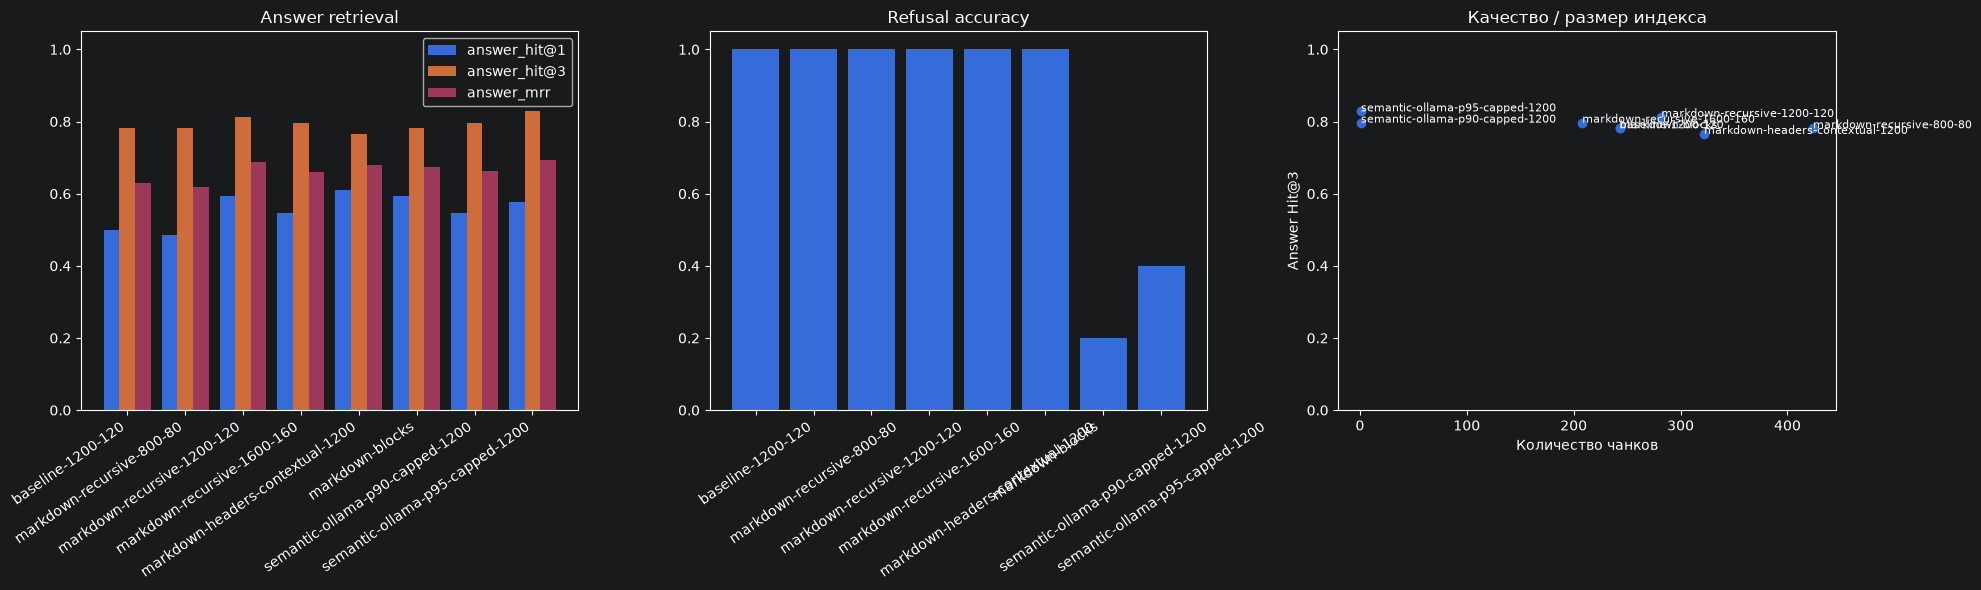

In [19]:
# ===== Графики: answer retrieval, refusal accuracy и размер индекса =====
try:
    import matplotlib.pyplot as plt

    MATPLOTLIB_AVAILABLE = True
except ImportError:
    MATPLOTLIB_AVAILABLE = False
    print("matplotlib не установлен: графики пропущены")

if MATPLOTLIB_AVAILABLE and EVAL_SUMMARY:
    strategy_names = list(EVAL_SUMMARY)
    figure, axes = plt.subplots(1, 3, figsize=(20, 6))

    width = 0.27
    for offset, metric in enumerate(("answer_hit@1", "answer_hit@3", "answer_mrr")):
        axes[0].bar(
            [index + offset * width for index in range(len(strategy_names))],
            [EVAL_SUMMARY[name][metric] for name in strategy_names],
            width=width,
            label=metric,
        )
    axes[0].set_xticks(
        [index + width for index in range(len(strategy_names))],
        strategy_names,
        rotation=35,
        ha="right",
    )
    axes[0].set_ylim(0, 1.05)
    axes[0].set_title("Answer retrieval")
    axes[0].legend()

    axes[1].bar(
        strategy_names,
        [EVAL_SUMMARY[name]["refusal_accuracy"] for name in strategy_names],
    )
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title("Refusal accuracy")
    axes[1].tick_params(axis="x", rotation=35)

    axes[2].scatter(
        [EVAL_SUMMARY[name]["chunks"] for name in strategy_names],
        [EVAL_SUMMARY[name]["answer_hit@3"] for name in strategy_names],
    )
    for name in strategy_names:
        axes[2].annotate(
            name,
            (EVAL_SUMMARY[name]["chunks"], EVAL_SUMMARY[name]["answer_hit@3"]),
            fontsize=8,
        )
    axes[2].set_xlabel("Количество чанков")
    axes[2].set_ylabel("Answer Hit@3")
    axes[2].set_ylim(0, 1.05)
    axes[2].set_title("Качество / размер индекса")

    figure.tight_layout()
    plt.show()
elif MATPLOTLIB_AVAILABLE:
    print("Нет EVAL_SUMMARY: сначала выполните ячейку оценки")


## 11. Сохранение прогона

`run.json` (настройки + источник), `results.json` (поиск по стратегиям),
`chunk_stats.json` (превью + итоги сборки), `eval.json` (метрики по голден-кейсам,
если оценка запускалась). Пути к собранным БД - в `run.json`.

In [20]:
RUN_DIR.mkdir(parents=True, exist_ok=True)


def write_json_atomic(path: Path, payload: object) -> None:
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )
    temporary.replace(path)


run_metadata = {
    "run_id": RUN_ID,
    "notebook": "chunking_strategies_experiments.ipynb",
    "saved_at": datetime.now(UTC).isoformat(),
    "config": {
        "source_database_name": database_path.name,
        "source_dump_run_id": dump_manifest.run_id,
        "embedding_space": database_manifest.embedding_space.model_dump(mode="json"),
        "strategies": {name: STRATEGY_PARAMS[name] for name in STRATEGIES},
        "max_documents": MAX_DOCUMENTS,
        "documents": [
            version_title.get(version.id, version.id) for version in SELECTED_VERSIONS
        ],
        "evidence_limit": EVIDENCE_LIMIT,
        "minimum_similarity_score": MINIMUM_SIMILARITY_SCORE,
        "case_limit": CASE_LIMIT,
        "cases": [asdict(case) for case in SELECTED_CASES],
        "deepeval": {
            "enabled": RUN_DEEPEVAL_JUDGE,
            "case_limit": DEEPEVAL_CASE_LIMIT,
            "strategies": list(DEEPEVAL_STRATEGIES),
            "threshold": DEEPEVAL_THRESHOLD,
            "judge_model": DEEPEVAL_JUDGE_MODEL,
        },
    },
    "built_databases": [
        {
            "strategy": built["strategy"],
            "database_path": str(built["database_path"]),
            "chunk_count": built["chunk_count"],
            "elapsed_s": built["elapsed_s"],
        }
        for built in BUILT_DATABASES
    ],
    "build_failures": BUILD_FAILURES,
}
write_json_atomic(RUN_DIR / "run.json", run_metadata)
write_json_atomic(RUN_DIR / "results.json", SEARCH_RESULTS)
write_json_atomic(RUN_DIR / "chunk_stats.json", PREVIEW_ROWS)
eval_rows = globals().get("EVAL_ROWS") or []
if eval_rows:
    write_json_atomic(RUN_DIR / "eval.json", eval_rows)
eval_summary = globals().get("EVAL_SUMMARY") or {}
if eval_summary:
    write_json_atomic(RUN_DIR / "eval_summary.json", eval_summary)
if RUN_DEEPEVAL_JUDGE:
    write_json_atomic(
        RUN_DIR / "deepeval.json",
        {
            "config": run_metadata["config"]["deepeval"],
            "rows": DEEPEVAL_ROWS,
            "summary": DEEPEVAL_SUMMARY,
        },
    )
print("Прогон сохранён:", RUN_DIR)
print("Сравнивайте results.json между прогонами: одни кейсы + один код -> один топ-N")

Прогон сохранён: /Users/zero/GITHUB/vue-graph-rag/mvp_v2/runtime/debug/chunking-experiments/2026-11-14/20261114T161951.435961Z
Сравнивайте results.json между прогонами: одни кейсы + один код -> один топ-N


## Мои заметки

- Какая стратегия лучше по вопросам поддержки:
- Что попробовать дальше (параметры, пороги, вопросы):